# Part 2 · The code: PEFT for a pretrained ViT

CS701 · W10 tutorial · TA Zichen

Open in Colab: **File → Save a copy in Drive** first.
We adapt one pretrained ViT to a small new dataset in six ways: training from scratch, full fine-tuning, linear probe,
and three PEFT methods (Adapter, AdaptFormer, LoRA).
Run the cells from top to bottom. Each training cell takes about one minute on a free Colab T4.

## 2.1 Setup

Use a GPU. In Colab, select **Runtime → Change runtime type → T4 GPU**.
The first cell sets where the data comes from.

In [1]:
DATA_URL = "https://huggingface.co/datasets/doem1997/cs701-w10-lora-data/resolve/main/w10_data.zip"
ZIP_SHA256 = "d7d03d58b681e7000ed01c7efd083a2986cea0a09ee4ba340d8679a694cf5b55"  # checks the download
LOCAL_ZIP = "w10_data.zip"  # if this file exists and is correct, the notebook does not download
SEED = 123

In [2]:
!pip install -q timm

In [3]:
import copy, hashlib, os, random, time, urllib.request, warnings, zipfile
import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
import torchvision as tv
from PIL import Image
from torch import nn

NAVY, AMBER, GREY = "#151C55", "#FFC000", "#B8BECC"  # frozen, trainable, other: the slide colours
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

In [4]:
assert torch.cuda.is_available(), "No GPU. In Colab: Runtime > Change runtime type > T4 GPU."
device = "cuda"
# T4: no real bfloat16, so we use float16 + a gradient scaler. Newer GPUs: bfloat16.
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
# float16: the gradient scaler may skip the first step. This is normal, so we hide the warning.
warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
print(torch.cuda.get_device_name(), "| autocast:", AMP_DTYPE, "| torch", torch.__version__, "| timm", timm.__version__)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

NVIDIA RTX PRO 6000 Blackwell Server Edition | autocast: torch.float16 | torch 2.9.0+cu128 | timm 1.0.24


## 2.2 Data

The data is a small part of EuroSAT: satellite photos of land use, 10 classes, 64 × 64 pixels.
We train on 20 images per class (200 images) and test on 100 per class (1,000 images).
EuroSAT: Helber et al., 2019, MIT licence.

In [5]:
def sha256(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()


if not os.path.exists(LOCAL_ZIP) or sha256(LOCAL_ZIP) != ZIP_SHA256:
    urllib.request.urlretrieve(DATA_URL, LOCAL_ZIP)  # download (again, if the old file is broken)
assert sha256(LOCAL_ZIP) == ZIP_SHA256, "The download is broken. Run this cell again."
zipfile.ZipFile(LOCAL_ZIP).extractall("w10_data")
classes = open("w10_data/classes.txt").read().split()  # index = line number
print(len(classes), "classes:", classes)

10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [6]:
mean = std = (0.5, 0.5, 0.5)  # the values this ViT checkpoint uses
train_tf = tv.transforms.Compose([
    tv.transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),  # 64 px -> 224 px, random crop
    tv.transforms.RandomHorizontalFlip(),
    tv.transforms.ToTensor(), tv.transforms.Normalize(mean, std)])
test_tf = tv.transforms.Compose([
    tv.transforms.Resize((224, 224)),
    tv.transforms.ToTensor(), tv.transforms.Normalize(mean, std)])

train_set = tv.datasets.ImageFolder("w10_data/train", train_tf)
test_set = tv.datasets.ImageFolder("w10_data/test", test_tf)
assert train_set.classes == test_set.classes == classes
print(len(train_set), "training images |", len(test_set), "test images")
test_loader = torch.utils.data.DataLoader(test_set, batch_size=128, num_workers=2)


def train_loader():  # a new generator with the same seed: same batches and crops for every method
    g = torch.Generator().manual_seed(SEED)
    return torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True, drop_last=True,
                                       num_workers=2, persistent_workers=True, generator=g)

200 training images | 1000 test images


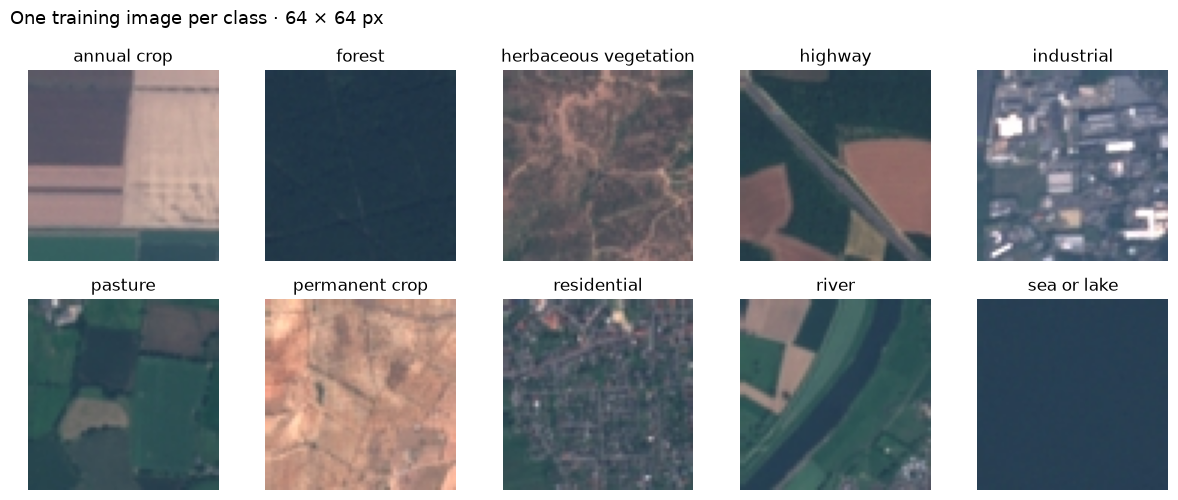

In [7]:
LABELS = {  # class folder -> the name on the slides
    "AnnualCrop": "annual crop", "Forest": "forest", "HerbaceousVegetation": "herbaceous vegetation",
    "Highway": "highway", "Industrial": "industrial", "Pasture": "pasture",
    "PermanentCrop": "permanent crop", "Residential": "residential", "River": "river",
    "SeaLake": "sea or lake",
}
fig, axes = plt.subplots(2, 5, figsize=(12, 5.0))
for c, ax in enumerate(axes.flat):
    path = next(p for p, label in train_set.samples if label == c)  # first training image of class c
    ax.imshow(Image.open(path))
    ax.set_title(LABELS[classes[c]], fontsize=12)
    ax.axis("off")
fig.suptitle("One training image per class · 64 × 64 px", x=0.01, ha="left", fontsize=13)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=0.86, wspace=0.05, hspace=0.2)
plt.show()

## 2.3 The pretrained ViT

We use ViT-B/16, pretrained on ImageNet-21k (`timm` name `vit_base_patch16_224.augreg_in21k`).
`new_vit()` loads it with a new, random head for our 10 classes.
The seed makes the head the same for every method.

In [8]:
def new_vit(pretrained=True):
    seed_everything()  # same random head for every method
    return timm.create_model("vit_base_patch16_224.augreg_in21k", pretrained=pretrained, num_classes=len(classes))


def n_weights(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


vit = new_vit().to(device).eval()  # the pretrained model: we keep it as a reference
N_VIT = n_weights(vit)
print(f"ViT-B/16 with a 10-class head: {N_VIT:,} weights ({N_VIT / 1e6:.1f} M)")
print(vit.blocks[0])

ViT-B/16 with a 10-class head: 85,806,346 weights (85.8 M)
Block(
  (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (attn): Attention(
    (qkv): Linear(in_features=768, out_features=2304, bias=True)
    (q_norm): Identity()
    (k_norm): Identity()
    (attn_drop): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (proj): Linear(in_features=768, out_features=768, bias=True)
    (proj_drop): Dropout(p=0.0, inplace=False)
  )
  (ls1): Identity()
  (drop_path1): Identity()
  (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU(approximate='none')
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (ls2): Identity()
  (drop_path2): Identity()
)


## 2.4 One train function for every method

Every method uses the same `train()` and `evaluate()`.
Only two things change: which weights are trainable, and the learning rate (LR).
`train()` uses AdamW, a one-cycle LR schedule with 10 % warm-up, batch 32 and 20 epochs.

In [9]:
@torch.no_grad()
def evaluate(model):
    model.eval()
    correct = 0
    for x, y in test_loader:
        with torch.autocast("cuda", AMP_DTYPE):
            pred = model(x.to(device)).argmax(1)
        correct += (pred.cpu() == y).sum().item()
    return correct / len(test_set)

In [10]:
def train(model, lr, epochs=20):
    seed_everything()
    loader = train_loader()
    model.to(device).train()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(loader), pct_start=0.1)
    scaler = torch.amp.GradScaler(enabled=(AMP_DTYPE == torch.float16))  # needed for float16 only
    hist = {"lr": lr, "epochs": epochs, "trainable": n_weights(model, True), "total": n_weights(model), "loss": []}
    print(f"trainable weights: {hist['trainable']:,} ({hist['trainable'] / N_VIT:.2%} of the ViT)")
    start = time.time()
    for epoch in range(1, epochs + 1):
        total = 0.0
        for x, y in loader:
            with torch.autocast("cuda", AMP_DTYPE):
                loss = nn.functional.cross_entropy(model(x.to(device)), y.to(device))
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            total += loss.item()
        hist["loss"].append(round(total / len(loader), 4))
        if epoch % 5 == 0:
            print(f"epoch {epoch:2d}/{epochs}   train loss {hist['loss'][-1]:.3f}")
    hist["seconds"] = round(time.time() - start, 1)
    hist["accuracy"] = evaluate(model)
    print(f"train time {hist['seconds']} s | test accuracy {hist['accuracy']:.1%}")
    return hist


results = {}  # one entry per method

## 2.5 Method 1: training from scratch

The same ViT-B/16, but with random weights (`pretrained=False`). All weights train, with LR 1e-4.
Your numbers can differ a little from the slides.

In [11]:
scratch_model = new_vit(pretrained=False)  # a new model: you can run this cell again
results["scratch"] = train(scratch_model, lr=1e-4)

trainable weights: 85,806,346 (100.00% of the ViT)


epoch  5/20   train loss 1.498


epoch 10/20   train loss 1.205


epoch 15/20   train loss 0.850


epoch 20/20   train loss 0.695


train time 9.0 s | test accuracy 60.3%


## 2.6 Method 2: full fine-tuning

Start from the pretrained ViT. Train all weights of the ViT and the head. Full fine-tuning needs a small LR: 1e-4.

In [12]:
fft_model = new_vit()  # all weights are trainable by default
results["full fine-tuning"] = train(fft_model, lr=1e-4)

trainable weights: 85,806,346 (100.00% of the ViT)


epoch  5/20   train loss 0.248


epoch 10/20   train loss 0.011


epoch 15/20   train loss 0.011


epoch 20/20   train loss 0.001


train time 8.3 s | test accuracy 90.9%


Full fine-tuning changes every weight. So each new task needs its own full copy of the model.

In [13]:
torch.save(fft_model.state_dict(), "fft_task.pt")
fft_mb = os.path.getsize("fft_task.pt") / 1e6
print(f"full fine-tuning: save {fft_mb:.1f} MB per task")

full fine-tuning: save 343.3 MB per task


## 2.7 Method 3: linear probe

Freeze the whole pretrained ViT. Train only the new head.

In [14]:
lp_model = new_vit()
lp_model.requires_grad_(False)  # freeze everything
lp_model.head.requires_grad_(True)  # the head trains
results["linear probe"] = train(lp_model, lr=1e-2)

trainable weights: 7,690 (0.01% of the ViT)


epoch  5/20   train loss 0.178


epoch 10/20   train loss 0.017


epoch 15/20   train loss 0.002


epoch 20/20   train loss 0.002


train time 3.9 s | test accuracy 89.2%


## 2.8 PEFT: small trainable modules in a frozen ViT

PEFT keeps the pretrained ViT frozen. It adds small trainable modules to each of the 12 blocks.
Each module has `down` (to a few numbers) and `up` (back to the size of the layer). `up` starts at zero, so a new PEFT
model gives exactly the pretrained output.
Fair rule: Adapter, AdaptFormer and LoRA use the same LR (3e-3), epochs, batch and seed, and about 25 K trainable
weights per block, plus the head.

In [15]:
PEFT_LR = 3e-3
x_check = next(iter(test_loader))[0].to(device)  # 128 test images for the checks


def peft_vit(add):  # a new frozen ViT; add(block) puts the small modules into one block
    model = new_vit()
    model.requires_grad_(False)  # freeze the pretrained ViT
    for block in model.blocks:
        add(block)  # the new modules are trainable
    model.head.requires_grad_(True)  # the new head trains too
    return model


@torch.no_grad()
def check_fresh(model):  # Check 1: a new PEFT model gives the pretrained output
    print(f"trainable weights per block: {n_weights(model.blocks[0], True):,}")
    model.to(device).eval()
    diff = (model(x_check) - vit(x_check)).abs().max().item()
    print("Check 1 · max |logit difference| to the pretrained ViT:", diff)
    return diff

## 2.9 Method 4: Adapter

An Adapter sits **after** the MLP of each block (serial): h + up(GELU(down(h))), where h is the MLP output.
The bottleneck is 16 numbers.

In [16]:
class Adapter(nn.Module):
    """Serial: y = h + up(GELU(down(h))), with h = MLP(x)."""

    def __init__(self, base, dim=768, bottleneck=16):
        super().__init__()
        self.base = base  # the MLP of the block (frozen)
        self.down = nn.Linear(dim, bottleneck)
        self.up = nn.Linear(bottleneck, dim)
        nn.init.zeros_(self.up.weight)  # up = 0: training starts from exactly the pretrained block
        nn.init.zeros_(self.up.bias)

    def forward(self, x):
        h = self.base(x)
        return h + self.up(nn.functional.gelu(self.down(h)))


def add_adapter(block):
    block.mlp = Adapter(block.mlp)

In [17]:
fresh_diff = {"Adapter": check_fresh(peft_vit(add_adapter))}

trainable weights per block: 25,360


Check 1 · max |logit difference| to the pretrained ViT: 0.0


In [18]:
adapter_model = peft_vit(add_adapter)  # a new model: you can run this cell again
results["Adapter"] = train(adapter_model, lr=PEFT_LR)

trainable weights: 312,010 (0.36% of the ViT)


epoch  5/20   train loss 0.103


epoch 10/20   train loss 0.003


epoch 15/20   train loss 0.003


epoch 20/20   train loss 0.006


train time 5.9 s | test accuracy 93.0%


## 2.10 Method 5: AdaptFormer

AdaptFormer sits **beside** the MLP (parallel). It gets the same input x as the MLP: MLP(x) + s · up(ReLU(down(x))).
The bottleneck is 16 numbers, and the scale s is 0.1.

In [19]:
class AdaptFormer(nn.Module):
    """Parallel: y = MLP(x) + s * up(ReLU(down(x)))."""

    def __init__(self, base, dim=768, bottleneck=16, s=0.1):
        super().__init__()
        self.base = base  # the MLP of the block (frozen)
        self.down = nn.Linear(dim, bottleneck)
        self.up = nn.Linear(bottleneck, dim)
        nn.init.zeros_(self.up.weight)  # up = 0: training starts from exactly the pretrained block
        nn.init.zeros_(self.up.bias)
        self.s = s

    def forward(self, x):
        return self.base(x) + self.s * self.up(nn.functional.relu(self.down(x)))


def add_adaptformer(block):
    block.mlp = AdaptFormer(block.mlp)

In [20]:
fresh_diff["AdaptFormer"] = check_fresh(peft_vit(add_adaptformer))

trainable weights per block: 25,360


Check 1 · max |logit difference| to the pretrained ViT: 0.0


In [21]:
adaptformer_model = peft_vit(add_adaptformer)  # a new model: you can run this cell again
results["AdaptFormer"] = train(adaptformer_model, lr=PEFT_LR)

trainable weights: 312,010 (0.36% of the ViT)


epoch  5/20   train loss 0.070


epoch 10/20   train loss 0.005


epoch 15/20   train loss 0.001


epoch 20/20   train loss 0.002


train time 6.3 s | test accuracy 93.8%


## 2.11 Method 6: LoRA

LoRA adds a small trainable branch beside a frozen layer W: y = W x + (α / r) · B A x.
We put it on `attn.qkv` (768 → 2,304) of each block, with r = 8 and α = 16.
A (`down`) maps 768 numbers to r numbers. B (`up`) maps the r numbers to 2,304 numbers and starts at zero.

In [22]:
class LoRA(nn.Module):
    """y = W x + (alpha / r) * B A x, where W is the wrapped (frozen) layer."""

    def __init__(self, base: nn.Linear, rank=8, alpha=16):
        super().__init__()
        self.base = base
        self.down = nn.Linear(base.in_features, rank, bias=False)  # A
        self.up = nn.Linear(rank, base.out_features, bias=False)  # B
        nn.init.zeros_(self.up.weight)  # B = 0: training starts from exactly the pretrained layer
        self.scale = alpha / rank

    def forward(self, x):
        return self.base(x) + self.scale * self.up(self.down(x))


def add_lora(block, rank=8, alpha=16):
    block.attn.qkv = LoRA(block.attn.qkv, rank, alpha)

In [23]:
fresh_diff["LoRA"] = check_fresh(peft_vit(add_lora))
qkv = LoRA(vit.blocks[0].attn.qkv)
w_qkv, a_qkv, b_qkv = qkv.base.weight.numel(), qkv.down.weight.numel(), qkv.up.weight.numel()
print(f"one qkv layer: W {w_qkv:,} weights (frozen) | A + B {a_qkv + b_qkv:,} weights ({(a_qkv + b_qkv) / w_qkv:.1%} of W)")

trainable weights per block: 24,576


Check 1 · max |logit difference| to the pretrained ViT: 0.0
one qkv layer: W 1,769,472 weights (frozen) | A + B 24,576 weights (1.4% of W)


In [24]:
lora_model = peft_vit(add_lora)  # a new model: you can run this cell again
results["LoRA"] = train(lora_model, lr=PEFT_LR)

trainable weights: 302,602 (0.35% of the ViT)


epoch  5/20   train loss 0.074


epoch 10/20   train loss 0.019


epoch 15/20   train loss 0.018


epoch 20/20   train loss 0.009


train time 6.3 s | test accuracy 92.7%


For each new task, a PEFT method saves only its small modules and the head. The pretrained ViT is shared by all tasks.

In [25]:
lora_weights = {name: p for name, p in lora_model.named_parameters() if p.requires_grad}  # A, B, head
torch.save(lora_weights, "lora_task.pt")
lora_mb = os.path.getsize("lora_task.pt") / 1e6
print(f"LoRA: save {lora_mb:.2f} MB per task | full fine-tuning: {fft_mb:.1f} MB")

LoRA: save 1.22 MB per task | full fine-tuning: 343.3 MB


## 2.12 LoRA only: merge, and switch off

**Check 2.** LoRA's branch is linear, so we can merge it into W: W' = W + (α / r) · B A.
The merged model is a normal ViT again, so inference has no extra cost.
Adapter and AdaptFormer have a GELU or ReLU inside, so they cannot be merged this way.

In [26]:
def merge(lora_layer):
    merged = copy.deepcopy(lora_layer.base)
    with torch.no_grad():
        merged.weight += lora_layer.scale * lora_layer.up.weight @ lora_layer.down.weight
    return merged


merged_model = copy.deepcopy(lora_model)
for block in merged_model.blocks:
    block.attn.qkv = merge(block.attn.qkv)

In [27]:
lora_model.eval()
merged_model.eval()
merge_diff, same = 0.0, 0
with torch.no_grad():  # float32 (no autocast): an exact comparison on all test images
    for x, _ in test_loader:
        merged_out, lora_out = merged_model(x.to(device)), lora_model(x.to(device))
        merge_diff = max(merge_diff, (merged_out - lora_out).abs().max().item())
        same += (merged_out.argmax(1) == lora_out.argmax(1)).sum().item()
merged_weights = n_weights(merged_model)
print("max |logit difference|, merged vs LoRA:", merge_diff)
print(f"same prediction on {same:,} / {len(test_set):,} test images")
print(f"weights: merged {merged_weights:,} | pretrained ViT {N_VIT:,}")

max |logit difference|, merged vs LoRA: 0.0003294944763183594
same prediction on 1,000 / 1,000 test images
weights: merged 85,806,346 | pretrained ViT 85,806,346


**Check 3.** When the scale is 0, the LoRA branch is off. Then the ViT body is the pretrained ViT again.
We compare the features before the head, because the head is new.

In [28]:
old_scale = lora_model.blocks[0].attn.qkv.scale
for block in lora_model.blocks:
    block.attn.qkv.scale = 0.0  # switch off
with torch.no_grad():
    off_diff = (lora_model.forward_features(x_check) - vit.forward_features(x_check)).abs().max().item()
print("max |feature difference|, LoRA off vs pretrained ViT:", off_diff)
for block in lora_model.blocks:
    block.attn.qkv.scale = old_scale  # switch on again

max |feature difference|, LoRA off vs pretrained ViT: 0.0


## 2.13 Compare the six methods

Same data, same seed, same `train()`. All three PEFT methods beat full fine-tuning.
AdaptFormer is best. Each PEFT method trains about 0.36 % of the weights.

In [29]:
ranked = sorted(results, key=lambda k: results[k]["accuracy"], reverse=True)
print(f"{'method':<18}{'trainable weights':>20}{'% of ViT':>10}{'test acc':>10}{'train s':>9}")
for name in ranked:
    h = results[name]
    print(f"{name:<18}{h['trainable']:>20,}{h['trainable'] / N_VIT:>10.2%}{h['accuracy']:>10.1%}{h['seconds']:>9.0f}")

method               trainable weights  % of ViT  test acc  train s
AdaptFormer                    312,010     0.36%     93.8%        6
Adapter                        312,010     0.36%     93.0%        6
LoRA                           302,602     0.35%     92.7%        6
full fine-tuning            85,806,346   100.00%     90.9%        8
linear probe                     7,690     0.01%     89.2%        4
scratch                     85,806,346   100.00%     60.3%        9


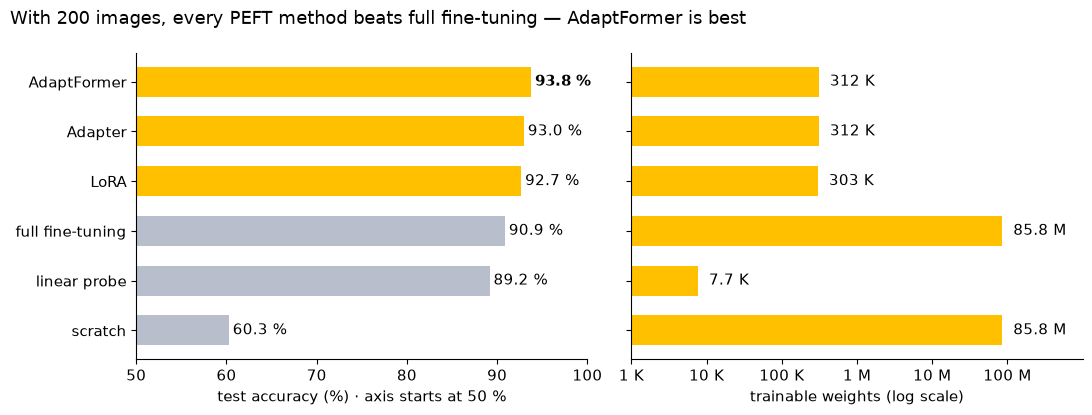

In [30]:
def short(n):  # 7,690 -> 7.7 K, 302,602 -> 303 K, 85,806,346 -> 85.8 M
    return f"{n / 1e6:.1f} M" if n >= 1e6 else f"{n / 1e3:.1f} K" if n < 1e4 else f"{n / 1e3:.0f} K"


PEFT = ["Adapter", "AdaptFormer", "LoRA"]
acc = [100 * results[k]["accuracy"] for k in ranked]
lo = min(70, 10 * int((min(acc) - 5) // 10))  # the accuracy axis starts here
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ax1.barh(ranked, [a - lo for a in acc], left=lo, height=0.6, color=[AMBER if k in PEFT else GREY for k in ranked])
for i, a in enumerate(acc):
    ax1.text(a + 0.4, i, f"{a:.1f} %", va="center", fontweight="bold" if i == 0 else "normal")
ax1.set(xlim=(lo, 100), xlabel=f"test accuracy (%) · axis starts at {lo} %")
ax2.barh(ranked, [results[k]["trainable"] for k in ranked], height=0.6, color=AMBER)
ax2.set(xscale="log", xlim=(1e3, 1e9), xlabel="trainable weights (log scale)")
ax2.set_xticks([1e3, 1e4, 1e5, 1e6, 1e7, 1e8], ["1 K", "10 K", "100 K", "1 M", "10 M", "100 M"])
ax2.xaxis.set_minor_locator(plt.NullLocator())
for i, k in enumerate(ranked):
    ax2.text(results[k]["trainable"] * 1.4, i, short(results[k]["trainable"]), va="center")
ax1.invert_yaxis()
peft_beats = all(results[k]["accuracy"] > results["full fine-tuning"]["accuracy"] for k in PEFT)
title = (f"With {len(train_set)} images, every PEFT method beats full fine-tuning — {ranked[0]} is best"
         if peft_beats else f"Test accuracy and trainable weights · {len(train_set)} training images")
fig.suptitle(title, fontsize=13, x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 2.14 Live ablation: the LR of LoRA

What happens if LoRA uses the LR of full fine-tuning (1e-4)?
We train one new LoRA model with LR 1e-4 and compare with the 3e-3 run above.

In [31]:
lora_slow = peft_vit(add_lora)
lora_slow_hist = train(lora_slow, lr=1e-4)
print(f"LoRA, LR 1e-4: {lora_slow_hist['accuracy']:.1%} | LoRA, LR 3e-3: {results['LoRA']['accuracy']:.1%}")

trainable weights: 302,602 (0.35% of the ViT)


epoch  5/20   train loss 1.976


epoch 10/20   train loss 0.968


epoch 15/20   train loss 0.646


epoch 20/20   train loss 0.571


train time 6.3 s | test accuracy 77.4%
LoRA, LR 1e-4: 77.4% | LoRA, LR 3e-3: 92.7%


The loss curves show the reason. With LR 1e-4, the train loss of LoRA goes down slowly.

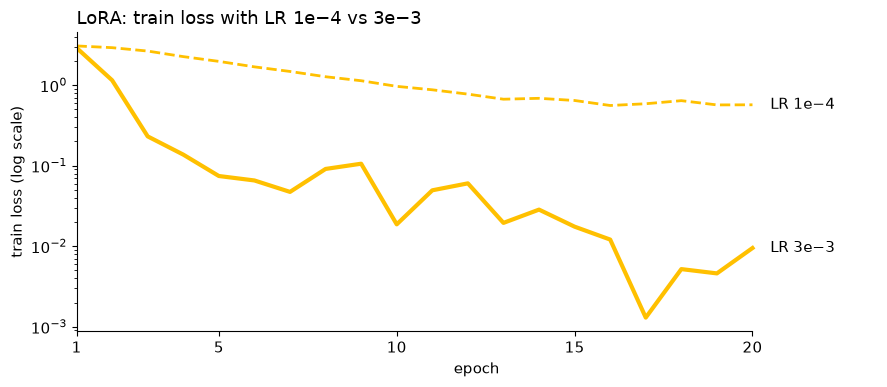

In [32]:
runs = [("LR 3e−3", results["LoRA"], AMBER, "-", 3.0), ("LR 1e−4", lora_slow_hist, AMBER, "--", 2.0)]
fig, ax = plt.subplots(figsize=(9, 4))
for name, h, color, style, width in runs:
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], style, color=color, lw=width)
    ax.text(20.5, h["loss"][-1], name, va="center")
ax.set_yscale("log")
ax.set_xlim(1, 23.5)
ax.set_xticks([1, 5, 10, 15, 20])
ax.spines["bottom"].set_bounds(1, 20)
ax.set_xlabel("epoch")
ax.set_ylabel("train loss (log scale)")
ax.set_title("LoRA: train loss with LR 1e−4 vs 3e−3", loc="left", fontsize=13)
plt.tight_layout()
plt.show()

## 2.15 Try at home

- Change the size: `Adapter(block.mlp, bottleneck=8)` or `32`; `LoRA(block.attn.qkv, rank=4, alpha=8)` or `rank=16, alpha=32`.
- Change the AdaptFormer scale `s` to 0.5 or 1.0.
- Put LoRA also on `attn.proj`, or on `mlp.fc1` and `mlp.fc2`.
- Each time, look at the trainable weights and the test accuracy.

# Part 3 · Your assignment

Open `sarbench/adapters.py` in your assignment code. Its `LoRA` class is the same as the class above.
`add_adapters` puts LoRA into `attn.qkv` and `attn.proj` of every block (rank 16, α = 32).
Adapter and AdaptFormer are not in `sarbench`. You can try them as an idea.

In [33]:
# For the TA only: save the numbers for the slides. It does nothing in Colab, so you can skip it.
if os.environ.get("W10_RESULTS_JSON"):
    import json
    peft_models = {"Adapter": adapter_model, "AdaptFormer": adaptformer_model, "LoRA": lora_model}
    run = dict(seed=SEED, gpu=torch.cuda.get_device_name(), autocast=str(AMP_DTYPE), vit_weights=N_VIT, methods=results,
               per_block={k: n_weights(m.blocks[0], True) for k, m in peft_models.items()},
               lr_ablation={"1e-4": lora_slow_hist, "3e-3": results["LoRA"]}, fft_save_mb=fft_mb, lora_save_mb=lora_mb,
               qkv_layer=dict(W=w_qkv, A=a_qkv, B=b_qkv, lora=a_qkv + b_qkv),
               checks=dict(fresh_diff=fresh_diff, merge_diff=merge_diff, merge_same_pred=same,
                           merged_weights=merged_weights, off_diff=off_diff))
    json.dump(run, open(os.environ["W10_RESULTS_JSON"], "w"), indent=1)